# How good is $\operatorname{Li}(x)$? The error term, the Riemann Hypothesis, and the quasi-Riemann Hypothesis

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part I, chapters "What is a good approximation?", "Square root error and random walks", "Cesàro smoothing" and "A view of $|\operatorname{Li}(X) - \pi(X)|$".*

Let $\pi(x)$ be the number of primes $p \le x$, and let
$$\operatorname{Li}(x) = \int_2^x \frac{dt}{\log t}$$
be Gauss's guess for it. The Prime Number Theorem says that $\pi(x)$ and $\operatorname{Li}(x)$ are asymptotic. As the book puts it in "The mystery moves to the error term":

> But if you are interested in the deep structure of your *mysterious quantity* perhaps all you have done is to manage to transport most questions about it to *Error*$(X)$.

So the real question is **how close** they are: the size of the error
$$E(x) = \operatorname{Li}(x) - \pi(x).$$

The Riemann Hypothesis is, in one of its many equivalent forms, the statement that this error is about as small as it could possibly be: roughly $\sqrt{x}$. In this notebook you will:

1. compare $\pi(x)$ with $\operatorname{Li}(x)$;
2. look at the error $E(x)$ itself, and see why it is so often close to $\sqrt{x}/\log x$;
3. smooth it out with a running (Cesàro) average;
4. see what the Riemann Hypothesis predicts about it, and what the newly proved **quasi-Riemann Hypothesis** gives.

Every plot has controls: change them and the plot redraws.

## Setting up: $\pi(n)$ and $\operatorname{Li}(n)$ for every $n$ up to a million

Rather than calling `prime_pi(n)` a million times, we sieve once and keep a running count. For $\operatorname{Li}$ we use the exponential integral: $\operatorname{li}(x) = \operatorname{Ei}(\log x)$, and $\operatorname{Li}(x) = \operatorname{li}(x) - \operatorname{li}(2)$.

In [1]:
import numpy as np
from scipy.special import expi

def prime_pi_table(B):
    "pi(n) for n = 0, 1, ..., B: one sieve, then a running count."
    is_prime = np.zeros(B + 1)
    is_prime[np.array(prime_range(B + 1))] = 1
    return np.cumsum(is_prime)

def Li_values(x):
    "Li(x) = li(x) - li(2), for a number or an array of numbers x >= 2."
    return expi(np.log(x)) - expi(np.log(2.0))

B_MAX = 10^6
PI = prime_pi_table(B_MAX)               # PI[n] = pi(n)
N = np.arange(2, B_MAX + 1, dtype=float)  # n = 2, 3, ..., B_MAX
LI = Li_values(N)                         # LI[n - 2] = Li(n)
E = LI - PI[2:]                           # E[n - 2] = Li(n) - pi(n)
print("pi(10^6) =", int(PI[10^6]), "  Li(10^6) =", round(LI[-1], 2), "  E(10^6) =", round(E[-1], 2))

pi(10^6) = 78498   Li(10^6) = 78626.5   E(10^6) = 128.5


A small helper: a plot of a million points is slow to draw and no clearer than one of a few thousand, so we thin the data to at most `points` points before plotting.

In [2]:
def thin(xs, ys, points=3000):
    "At most `points` of the points (xs[i], ys[i]), evenly spread."
    step = max(1, len(xs) // points)
    return list(zip(xs[::step], ys[::step]))

## 1. $\pi(x)$ and $\operatorname{Li}(x)$

From far away the two curves are indistinguishable, which is the Prime Number Theorem. For comparison, the dashed curve is the cruder approximation $x/\log x$. Try small $X$ (where the staircase of $\pi(x)$ is visible) and large $X$.

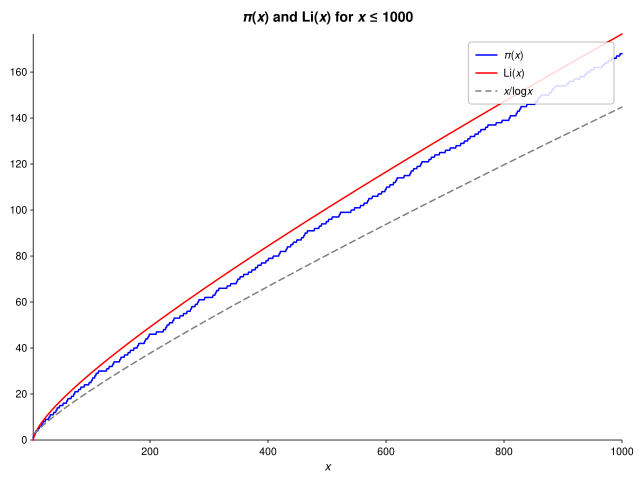

In [3]:
@interact
def pi_and_Li(X=selector([100, 1000, 10^4, 10^5, 10^6], default=1000, label='x up to')):
    n = int(X) - 1
    g = list_plot(thin(N[:n], PI[2:X + 1]), plotjoined=True, color='blue', legend_label=r'$\pi(x)$')
    g += list_plot(thin(N[:n], LI[:n]), plotjoined=True, color='red', legend_label=r'$\mathrm{Li}(x)$')
    g += plot(lambda t: t / log(t), (2, X), color='gray', linestyle='--', legend_label=r'$x/\log x$')
    show(g, axes_labels=['$x$', ''], title=r'$\pi(x)$ and $\mathrm{Li}(x)$ for $x \leq %s$' % X)

## 2. The error $E(x) = \operatorname{Li}(x) - \pi(x)$

Now look at the difference. Two things stand out:

* **It is positive.** For every $x$ we can compute, $\operatorname{Li}(x)$ overestimates $\pi(x)$. (In fact this holds for all $2 \le x \le 10^{19}$.) It is *not* true forever: Littlewood proved in 1914 that $E(x)$ changes sign infinitely often. The first sign change is believed to lie near $1.397 \times 10^{316}$; see the notebook on Skewes' number.
* **It is small**, on the scale of $\sqrt{x}$.

The orange curve is $\tfrac{1}{2}\operatorname{li}(\sqrt{x}) \approx \sqrt{x}/\log x$. The reason it fits so well: $\operatorname{Li}(x)$ is really a better approximation to a *weighted* count of prime powers,
$$\pi(x) + \tfrac{1}{2}\pi(x^{1/2}) + \tfrac{1}{3}\pi(x^{1/3}) + \cdots,$$
than to $\pi(x)$ itself (this comes out of Riemann's explicit formula). So $\operatorname{Li}(x) - \pi(x)$ contains the term $\tfrac{1}{2}\pi(\sqrt{x}) \approx \tfrac{1}{2}\operatorname{li}(\sqrt{x})$ coming from the squares of primes, which explains both the sign and the size. The rest, the part that wiggles, is what the zeros of $\zeta(s)$ control.

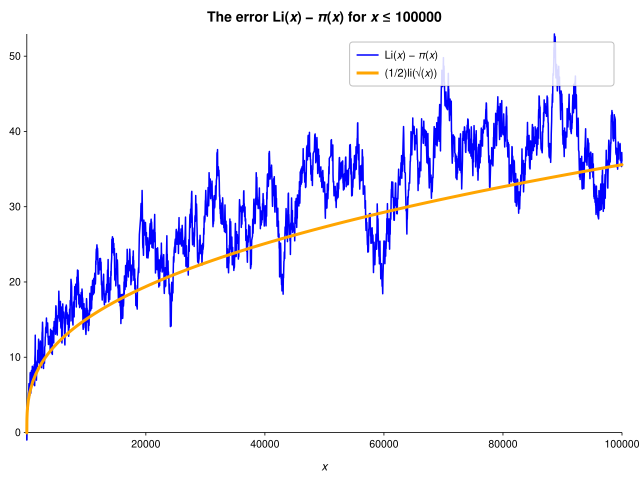

In [4]:
@interact
def the_error(X=selector([1000, 10^4, 10^5, 10^6], default=10^5, label='x up to'),
              bias=checkbox(True, label='show the prime-squares term')):
    n = int(X) - 1
    g = list_plot(thin(N[:n], E[:n]), plotjoined=True, color='blue', legend_label=r'$\mathrm{Li}(x) - \pi(x)$')
    if bias:
        g += plot(lambda t: expi(0.5 * float(log(t))) / 2, (2, X), color='orange', thickness=2,
                  legend_label=r'$\frac{1}{2}\mathrm{li}(\sqrt{x})$')
    show(g, axes_labels=['$x$', ''], title=r'The error $\mathrm{Li}(x) - \pi(x)$ for $x \leq %s$' % X)

## 3. Smoothing the error: the running (Cesàro) average

The error is jagged: it jumps down by one at every prime. A good way to see its trend is to average it, as the book does in the chapter on Cesàro smoothing:
$$\bar E(x) = \frac{1}{x} \int_2^x E(t)\, dt \;\approx\; \frac{1}{x}\sum_{n \le x} E(n).$$
Below, $E(x)$ is blue, its running average red, and the purple curve is the comparison you choose. The running average is much smoother than $E(x)$ and grows like $\sqrt{x}/\log x$, as section 2 suggests; which constant multiple fits best is a good question to explore.

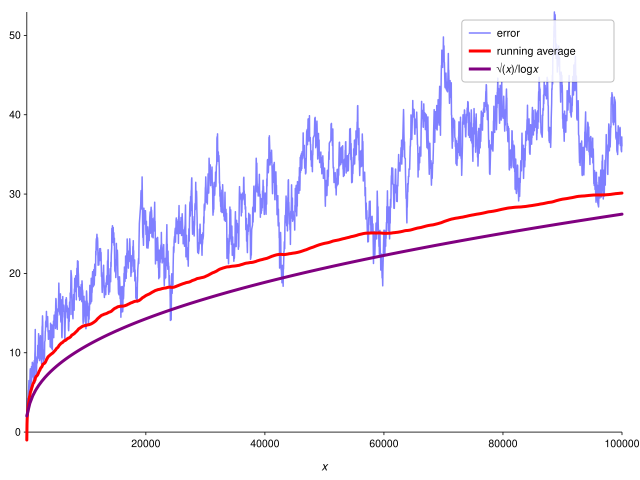

In [5]:
RUNNING = np.cumsum(E) / np.arange(1, len(E) + 1)

COMPARE = {    # (the menu's words, the curve, its legend)
    'sqrt(x) / log(x)': (lambda t: sqrt(t) / log(t), r'$\sqrt{x}/\log x$'),
    'sqrt(2/pi) sqrt(x / log(x))': (lambda t: sqrt(2 / pi) * sqrt(t / log(t)), r'$\sqrt{2/\pi}\,\sqrt{x/\log x}$'),
    'sqrt(x)': (lambda t: sqrt(t), r'$\sqrt{x}$'),
}

@interact
def running_average(X=selector([10^4, 10^5, 10^6], default=10^5, label='x up to'),
                    curve=selector(list(COMPARE), label='compare with')):
    n = int(X) - 1
    g = list_plot(thin(N[:n], E[:n]), plotjoined=True, color='blue', alpha=0.5, legend_label='error')
    g += list_plot(thin(N[:n], RUNNING[:n]), plotjoined=True, color='red', thickness=2, legend_label='running average')
    f, legend = COMPARE[curve]
    g += plot(f, (2, X), color='purple', thickness=2, legend_label=legend)
    show(g, axes_labels=['$x$', ''])

## 4. What the Riemann Hypothesis says about $E(x)$

In 1901 von Koch showed that the Riemann Hypothesis is **equivalent** to
$$|\operatorname{Li}(x) - \pi(x)| = O(\sqrt{x}\,\log x),$$
and Schoenfeld (1976) made the constant explicit: *if* the Riemann Hypothesis is true, then
$$|\operatorname{li}(x) - \pi(x)| < \frac{1}{8\pi}\sqrt{x}\,\log x \qquad \text{for all } x \ge 2657.$$
(Here $\operatorname{li}(x) = \operatorname{Li}(x) + \operatorname{li}(2)$ with $\operatorname{li}(2) \approx 1.045$, which makes no visible difference.)

The table compares the actual error with Schoenfeld's bound at powers of ten, using the known values of $\pi(10^k)$ (OEIS A006880) for $k$ up to $24$. The bound only applies from $x \ge 2657$, so ignore the first rows. From there on the error stays comfortably below the bound, and the ratio keeps shrinking: the $\log x$ is generous.

In [6]:
import mpmath
mpmath.mp.dps = 40

# pi(10^k), from OEIS A006880
PI_POWERS_OF_TEN = {
    1: 4, 2: 25, 3: 168, 4: 1229, 5: 9592, 6: 78498, 7: 664579, 8: 5761455, 9: 50847534,
    10: 455052511, 11: 4118054813, 12: 37607912018, 13: 346065536839, 14: 3204941750802,
    15: 29844570422669, 16: 279238341033925, 17: 2623557157654233, 18: 24739954287740860,
    19: 234057667276344607, 20: 2220819602560918840, 21: 21127269486018731928,
    22: 201467286689315906290, 23: 1925320391606803968923, 24: 18435599767349200867866,
}

rows = [['$k$', r'$\pi(10^k)$', r'$\mathrm{Li}(10^k) - \pi(10^k)$', r'$\frac{1}{8\pi}\sqrt{x}\log x$', 'error / bound']]
for k, p in PI_POWERS_OF_TEN.items():
    x = mpmath.mpf(10)**k
    err = mpmath.li(x, offset=True) - p
    bound = mpmath.sqrt(x) * mpmath.log(x) / (8 * mpmath.pi)
    rows.append([k, p, mpmath.nstr(err, 8), mpmath.nstr(bound, 8), mpmath.nstr(err / bound, 3)])
table(rows, header_row=True)

| $k$ | $\pi(10^k)$ | $\mathrm{Li}(10^k) - \pi(10^k)$ | $\frac{1}{8\pi}\sqrt{x}\log x$ | error / bound |
|:---|:---|:---|:---|:---|
| $1$ | $4$ | 1.1204357 | 0.28971823 | 3.87 |
| $2$ | $25$ | 4.0809778 | 1.832339 | 2.23 |
| $3$ | $168$ | 8.5644942 | 8.691547 | 0.985 |
| $4$ | $1229$ | 16.092052 | 36.64678 | 0.439 |
| $5$ | $9592$ | 36.763837 | 144.85912 | 0.254 |
| $6$ | $78498$ | 128.504 | 549.7017 | 0.234 |
| $7$ | $664579$ | 338.35988 | 2028.0276 | 0.167 |
| $8$ | $5761455$ | 753.33028 | 7329.356 | 0.103 |
| $9$ | $50847534$ | 1699.9118 | 26074.641 | 0.0652 |
| $10$ | $455052511$ | 3102.5415 | 91616.95 | 0.0339 |
| $11$ | $4118054813$ | 11586.576 | 318690.06 | 0.0364 |
| $12$ | $37607912018$ | 38261.76 | 1099403.4 | 0.0348 |
| $13$ | $346065536839$ | 108970.01 | 3766337.0 | 0.0289 |
| $14$ | $3204941750802$ | 314888.91 | 12826373.0 | 0.0246 |
| $15$ | $29844570422669$ | 1052617.5 | 43457735.0 | 0.0242 |
| $16$ | $279238341033925$ | 3214630.7 | 1.4658712e+8 | 0.0219 |
| $17$ | $2623557157654233$ | 7956587.7 | 4.92521e+8 | 0.0162 |
| $18$ | $24739954287740860$ | 21949554.0 | 1.6491051e+9 | 0.0133 |
| $19$ | $234057667276344607$ | 99877774.0 | 5.5046464e+9 | 0.0181 |
| $20$ | $2220819602560918840$ | 2.2274464e+8 | 1.832339e+10 | 0.0122 |
| $21$ | $21127269486018731928$ | 5.9739425e+8 | 6.0840829e+10 | 0.00982 |
| $22$ | $201467286689315906290$ | 1.9323552e+9 | 2.0155729e+11 | 0.00959 |
| $23$ | $1925320391606803968923$ | 7.2501862e+9 | 6.6635194e+11 | 0.0109 |
| $24$ | $18435599767349200867866$ | 1.7146907e+10 | 2.1988068e+12 | 0.0078 |

## 5. The quasi-Riemann Hypothesis: a major new theorem (2026)

The Riemann Hypothesis says that every nontrivial zero $\rho$ of $\zeta(s)$ has real part exactly $\tfrac12$. Since 1896 we have known only that the zeros lie in the open strip $0 < \operatorname{Re}(\rho) < 1$; every known zero-free region gets thinner and thinner as you go up the strip, so none of them rules out zeros creeping arbitrarily close to the line $\operatorname{Re}(s) = 1$.

The **quasi-Riemann Hypothesis** asks for much less than RH, but something that had been out of reach for over a century: a strip of *fixed* width. Precisely, $\mathrm{QRH}(a)$ says that every nontrivial zero satisfies
$$a \;\le\; \operatorname{Re}(\rho) \;\le\; 1 - a$$
for some fixed $a > 0$ (RH is the extreme case $a = \tfrac12$).

In October 2026 OpenAI announced AI-generated proofs of the quasi-Riemann Hypothesis:

* a 49-page proof of $\mathrm{QRH}(1/12)$: all nontrivial zeros satisfy $\tfrac{1}{12} \le \operatorname{Re}(\rho) \le \tfrac{11}{12}$. Number theorists who have worked through it (including Maksym Radziwiłł and Alexander Dunn) largely agree that it is correct; the argument is a synthesis of known ideas, built around metaplectic forms;
* a longer (199-page) proof of $\mathrm{QRH}(1/8)$, formally verified in Lean, which mathematicians have so far set aside in favour of the shorter argument.

As of late 2026 neither paper had been through journal peer review, and some experts (for example Peter Sarnak) prefer to wait until every detail has been checked by people before calling it a theorem. See *[AI Proved the Quasi-Riemann Hypothesis. What Happens Now?](https://www.quantamagazine.org/ai-proved-the-quasi-riemann-hypothesis-what-happens-now-20261019/)* (Quanta Magazine, 19 October 2026) and John Baez's *[The Quasi-Riemann Hypothesis](https://johncarlosbaez.wordpress.com/2026/10/21/the-quasi-riemann-hypothesis/)* (21 October 2026).

**What it means for primes.** Just as RH gives an error of about $\sqrt{x}$, $\mathrm{QRH}(a)$ gives
$$|\operatorname{Li}(x) - \pi(x)| = O(x^{\theta}) \qquad \text{for every } \theta > 1 - a,$$
so $\mathrm{QRH}(1/12)$ gives every exponent $\theta > \tfrac{11}{12}$ (and $\mathrm{QRH}(1/8)$ would give $\theta > \tfrac78$). Before 2026 no bound of the form $O(x^{\theta})$ with any $\theta < 1$ was known. As Radziwiłł put it, *"in a sense, the vast majority of consequences of RH already follow from quasi-RH."*

The plot below uses logarithmic scales on both axes, where a power $x^{\theta}$ is a straight line of slope $\theta$. The constants in these theorems are not explicit, so only the slopes are meaningful. The purple line $x^{\theta}$ starts at $\theta = \tfrac12$, where it runs parallel to the data; drag $\theta$ up to $\tfrac{11}{12}$ to see how much room the new theorem still leaves above what the data shows, and what the Riemann Hypothesis predicts.

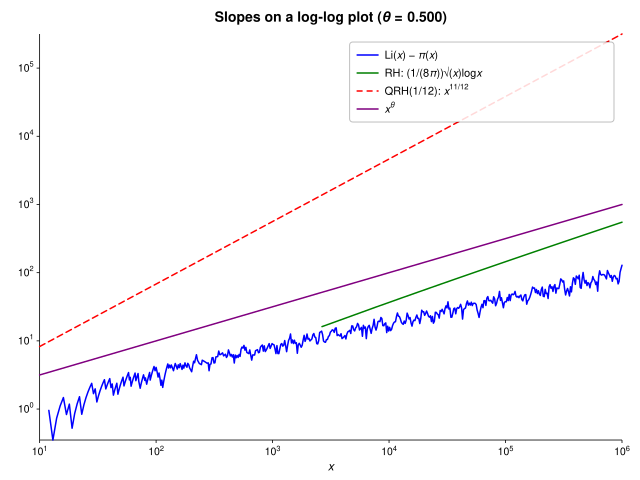

In [7]:
@interact
def exponents(theta=slider(0.5, 1.0, 1/96, 1/2, label='exponent theta')):
    n = len(E)
    idx = np.unique(np.logspace(1, np.log10(n - 1), 600).astype(int))
    pts = [(N[i], E[i]) for i in idx if E[i] > 0]
    g = list_plot(pts, plotjoined=True, color='blue', scale='loglog', legend_label=r'$\mathrm{Li}(x) - \pi(x)$')
    g += plot(lambda t: sqrt(t) * log(t) / (8 * pi), (2657, B_MAX), color='green', scale='loglog',
              legend_label=r'RH: $\frac{1}{8\pi}\sqrt{x}\log x$')
    g += plot(lambda t: t^(11/12), (10, B_MAX), color='red', linestyle='--', scale='loglog',
              legend_label=r'QRH(1/12): $x^{11/12}$')
    g += plot(lambda t: t^theta, (10, B_MAX), color='purple', scale='loglog', legend_label=r'$x^{\theta}$')
    show(g, axes_labels=['$x$', ''], title=r'Slopes on a log-log plot ($\theta = %.3f$)' % theta)

## Things to try

1. In section 3, which comparison curve fits the running average best as $X$ grows? Can you explain the constant in $\sqrt{2/\pi}\,\sqrt{x/\log x}$ using the notebook on random walks?
2. Modify the code in section 2 to plot $E(x) - \tfrac{1}{2}\operatorname{li}(\sqrt{x})$. What is left, and how big is it?
3. Extend the table in section 4: what happens to the column "error / bound" if you replace $\log x$ by $\log\log x$?
4. Suppose a zero $\rho$ of $\zeta(s)$ had real part $0.9$. Roughly how large could $E(x)$ get? (Hint: each zero contributes a term of size about $x^{\operatorname{Re}\rho}/|\rho|$ to the explicit formula.)

---
*Adapted and greatly expanded from the worksheets that produced figures for* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*